## Experiment: Welch's test from summary statistics.

In [1]:
import numpy as np
from scipy import stats

n1, mean1, sd1 = 12, 82.0, 15.0
n2, mean2, sd2 = 18, 70.0, 8.0

difference = mean1 - mean2
a = sd1**2 / n1
b = sd2**2 / n2
se = np.sqrt(a + b)
df = (a + b)**2 / (a**2 / (n1 - 1) + b**2 / (n2 - 1))
t_statistic = difference / se
p_value = 2 * stats.t.sf(abs(t_statistic), df)

critical = stats.t.ppf(0.975, df)
ci_low = difference - critical * se
ci_high = difference + critical * se

print(f"Difference in means: {difference:.4f}")
print(f"Standard error: {se:.4f}")
print(f"Welch degrees of freedom: {df:.4f}")
print(f"t-statistic: {t_statistic:.4f}")
print(f"Two-sided p-value: {p_value:.4f}")
print(f"95% confidence interval: [{ci_low:.4f}, {ci_high:.4f}]")

# Verify against SciPy using the same summary statistics.
check = stats.ttest_ind_from_stats(
    mean1, sd1, n1, mean2, sd2, n2,
    equal_var=False
)

# Experiment: exchange the two groups.
# Which reported values change sign, and which do not?

Difference in means: 12.0000
Standard error: 4.7229
Welch degrees of freedom: 15.2134
t-statistic: 2.5408
Two-sided p-value: 0.0224
95% confidence interval: [1.9457, 22.0543]


## Experiment: pooled and Welch tests on the same observations.

In [2]:
import numpy as np
from scipy import stats

# Unequal sample sizes and noticeably different spreads.
a = np.array([28, 37, 41, 45, 53, 62, 75, 88], dtype=float)
b = np.array([
    41, 45, 47, 49, 50, 51, 52, 53,
    54, 55, 56, 57, 58, 59, 60, 61,
    62, 63, 64, 65, 66, 67, 68, 70
], dtype=float)

pooled = stats.ttest_ind(a, b, equal_var=True)
welch = stats.ttest_ind(a, b, equal_var=False)

print("Group sizes:", len(a), len(b))
print("Sample SDs:", np.std(a, ddof=1), np.std(b, ddof=1))
print(f"Difference of means: {a.mean() - b.mean():.3f}")
print(f"Pooled: t={pooled.statistic:.4f}, p={pooled.pvalue:.4f}")
print(f"Welch:  t={welch.statistic:.4f}, p={welch.pvalue:.4f}")

# The difference is always computed in the same order: A - B.
# Experiment: reduce A's variance without changing its mean.

Group sizes: 8 24
Sample SDs: 20.269170819603985 7.740234614277397
Difference of means: -3.583
Pooled: t=-0.7371, p=0.4668
Welch:  t=-0.4883, p=0.6390


## Experiment: visual diagnostics for two independent groups.

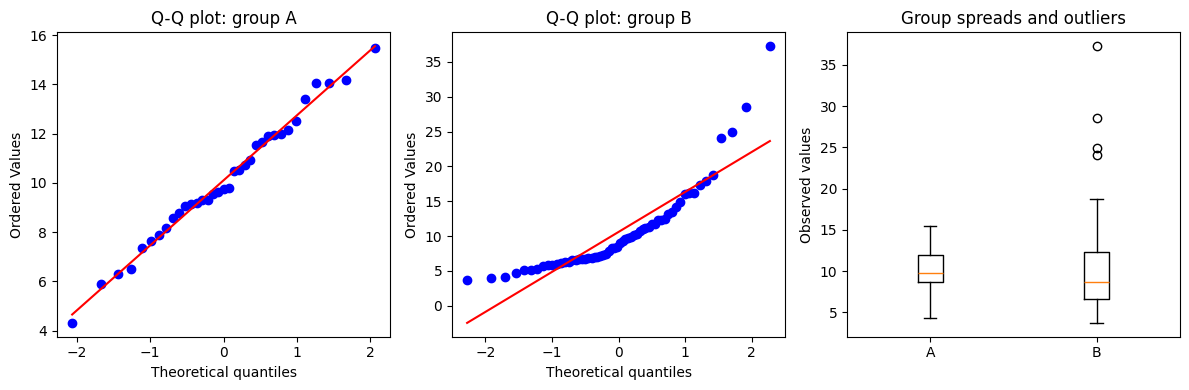

Group A: n = 35 SD = 2.5662122795470026
Group B: n = 60 SD = 6.287937624303809


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)

# Illustrative distributions with unequal spreads and some skewness.
group_a = rng.normal(loc=10, scale=3, size=35)
group_b = rng.lognormal(mean=2.2, sigma=0.45, size=60)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

stats.probplot(group_a, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: group A")

stats.probplot(group_b, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: group B")

axes[2].boxplot([group_a, group_b])
axes[2].set_xticks([1, 2], ["A", "B"])
axes[2].set_title("Group spreads and outliers")
axes[2].set_ylabel("Observed values")

fig.tight_layout()
fig.savefig(
    "../../images/welch_diagnostics.png", dpi=180, bbox_inches="tight"
)
plt.show()

print("Group A: n =", len(group_a), "SD =", group_a.std(ddof=1))
print("Group B: n =", len(group_b), "SD =", group_b.std(ddof=1))

# Experiment: replace group B with normal observations.
# Does the appearance of its Q-Q plot change?

## Experiment: type I error under unequal variances and sample sizes.

Equal variances: pooled=0.045, Welch=0.044
High SD, small n: pooled=0.249, Welch=0.045
High SD, large n: pooled=0.002, Welch=0.050
Equal group sizes: pooled=0.050, Welch=0.045


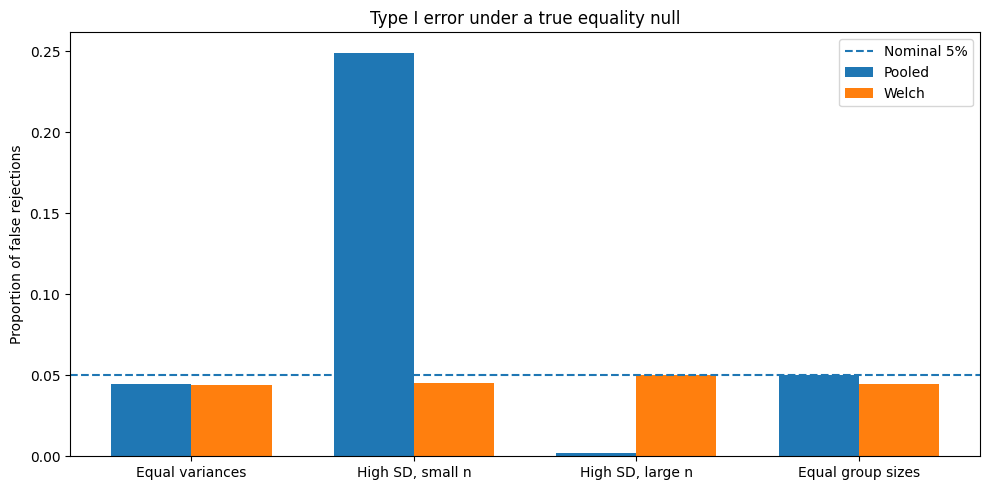

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
repetitions = 5000
alpha = 0.05

# Both populations have mean zero: H0 is true.
scenarios = [
    (20, 20, 1, 1, "Equal variances"),
    (10, 40, 3, 1, "High SD, small n"),
    (40, 10, 3, 1, "High SD, large n"),
    (20, 20, 3, 1, "Equal group sizes"),
]

pooled_rates = []
welch_rates = []
labels = []

for n1, n2, sd1, sd2, label in scenarios:
    x = rng.normal(0, sd1, size=(repetitions, n1))
    y = rng.normal(0, sd2, size=(repetitions, n2))

    pooled = stats.ttest_ind(x, y, axis=1, equal_var=True)
    welch = stats.ttest_ind(x, y, axis=1, equal_var=False)

    pooled_rate = np.mean(pooled.pvalue < alpha)
    welch_rate = np.mean(welch.pvalue < alpha)

    pooled_rates.append(pooled_rate)
    welch_rates.append(welch_rate)
    labels.append(label)

    print(
        f"{label}: pooled={pooled_rate:.3f}, "
        f"Welch={welch_rate:.3f}"
    )

positions = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(positions - width / 2, pooled_rates, width, label="Pooled")
ax.bar(positions + width / 2, welch_rates, width, label="Welch")
ax.axhline(alpha, linestyle="--", label="Nominal 5%")

ax.set_xticks(positions, labels)
ax.set_ylabel("Proportion of false rejections")
ax.set_title("Type I error under a true equality null")
ax.legend()
fig.tight_layout()
fig.savefig(
    "../../images/welch_type1_rates.png", dpi=180, bbox_inches="tight"
)
plt.show()

# Experiment: change the variance ratio or group-size imbalance.

## Experiment: coverage of pooled and Welch confidence intervals.

Equal SD: pooled=0.943, Welch=0.944
High SD, small n: pooled=0.731, Welch=0.946
High SD, large n: pooled=0.999, Welch=0.949


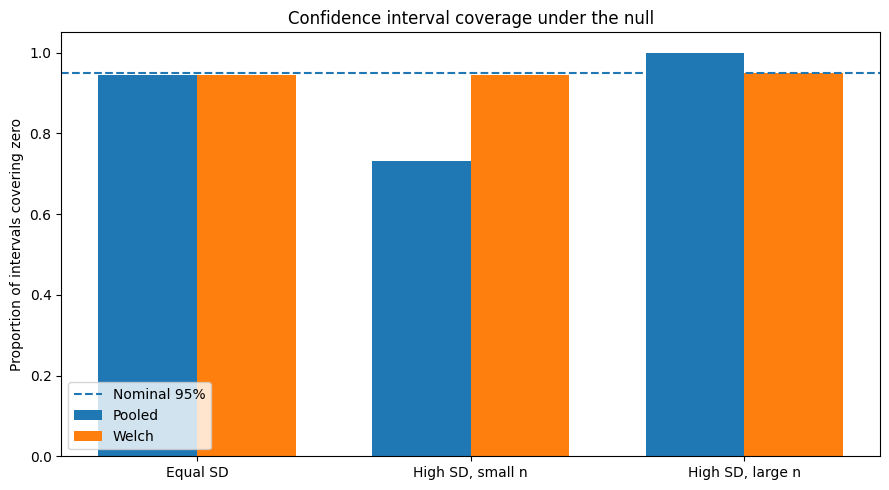

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2027)
repetitions = 4000
alpha = 0.05

scenarios = [
    (20, 20, 1, 1, "Equal SD"),
    (10, 40, 3, 1, "High SD, small n"),
    (40, 10, 3, 1, "High SD, large n"),
]

pooled_coverages = []
welch_coverages = []
labels = []

for n1, n2, sd1, sd2, label in scenarios:
    x = rng.normal(0, sd1, size=(repetitions, n1))
    y = rng.normal(0, sd2, size=(repetitions, n2))

    differences = x.mean(axis=1) - y.mean(axis=1)
    v1 = x.var(axis=1, ddof=1)
    v2 = y.var(axis=1, ddof=1)

    # Welch intervals.
    a = v1 / n1
    b = v2 / n2
    se_w = np.sqrt(a + b)
    df_w = (a + b)**2 / (a**2 / (n1 - 1) + b**2 / (n2 - 1))
    margin_w = stats.t.ppf(1 - alpha / 2, df_w) * se_w
    coverage_w = np.mean(np.abs(differences) <= margin_w)

    # Pooled intervals.
    pooled_var = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
    se_p = np.sqrt(pooled_var * (1 / n1 + 1 / n2))
    margin_p = stats.t.ppf(1 - alpha / 2, n1 + n2 - 2) * se_p
    coverage_p = np.mean(np.abs(differences) <= margin_p)

    pooled_coverages.append(coverage_p)
    welch_coverages.append(coverage_w)
    labels.append(label)
    print(f"{label}: pooled={coverage_p:.3f}, Welch={coverage_w:.3f}")

positions = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(positions - width / 2, pooled_coverages, width, label="Pooled")
ax.bar(positions + width / 2, welch_coverages, width, label="Welch")
ax.axhline(0.95, linestyle="--", label="Nominal 95%")
ax.set_xticks(positions, labels)
ax.set_ylabel("Proportion of intervals covering zero")
ax.set_ylim(0, 1.05)
ax.set_title("Confidence interval coverage under the null")
ax.legend()
fig.tight_layout()
fig.savefig(
    "../../images/welch_ci_coverage.png", dpi=180, bbox_inches="tight"
)
plt.show()

# Experiment: repeat with samples drawn from a skewed distribution.

## Experiment: Welch-test power and sample allocation.

nA=30, nB=90: SE=0.5578, simulated power=0.407
nA=60, nB=60: SE=0.4082, simulated power=0.666
nA=90, nB=30: SE=0.3651, simulated power=0.769


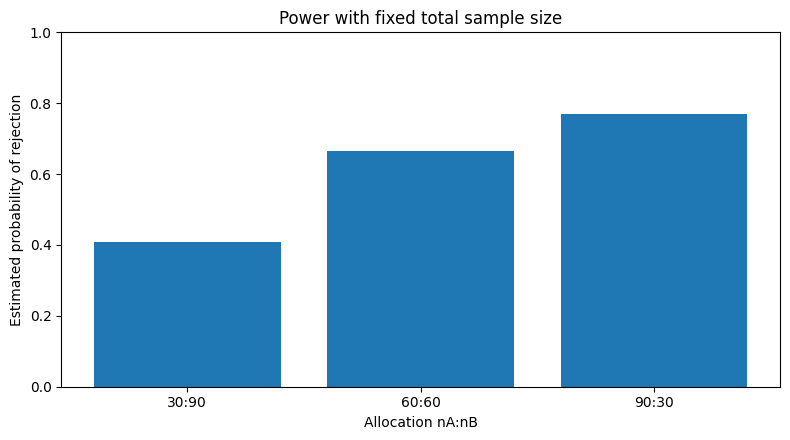

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
repetitions = 3000
alpha = 0.05

# Group A has greater variability than group B.
mean_a, mean_b = 1.0, 0.0
sd_a, sd_b = 3.0, 1.0

# Each design has the same total sample size N = 120.
allocations = [(30, 90), (60, 60), (90, 30)]
powers = []

for n_a, n_b in allocations:
    a = rng.normal(mean_a, sd_a, size=(repetitions, n_a))
    b = rng.normal(mean_b, sd_b, size=(repetitions, n_b))

    result = stats.ttest_ind(a, b, axis=1, equal_var=False)
    power = np.mean(result.pvalue < alpha)
    powers.append(power)

    theoretical_se = np.sqrt(sd_a**2 / n_a + sd_b**2 / n_b)
    print(
        f"nA={n_a}, nB={n_b}: "
        f"SE={theoretical_se:.4f}, simulated power={power:.3f}"
    )

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar([f"{a}:{b}" for a, b in allocations], powers)
ax.set_xlabel("Allocation nA:nB")
ax.set_ylabel("Estimated probability of rejection")
ax.set_ylim(0, 1)
ax.set_title("Power with fixed total sample size")
fig.tight_layout()
fig.savefig(
    "../../images/welch_power_allocation.png", dpi=180, bbox_inches="tight"
)
plt.show()

# Experiment: increase the true difference or the total N.

##  Experiment: Welch's t-test for two graduate-salary groups.

Observations per group: 50
Political Science mean: 33258.25
Social Sciences mean: 29989.87
Difference (Political - Social): 3268.38
Welch t-statistic: 2.6232
Welch p-value: 0.0102
Welch degrees of freedom: 88.98
95% CI for mean difference: [792.68, 5744.08]


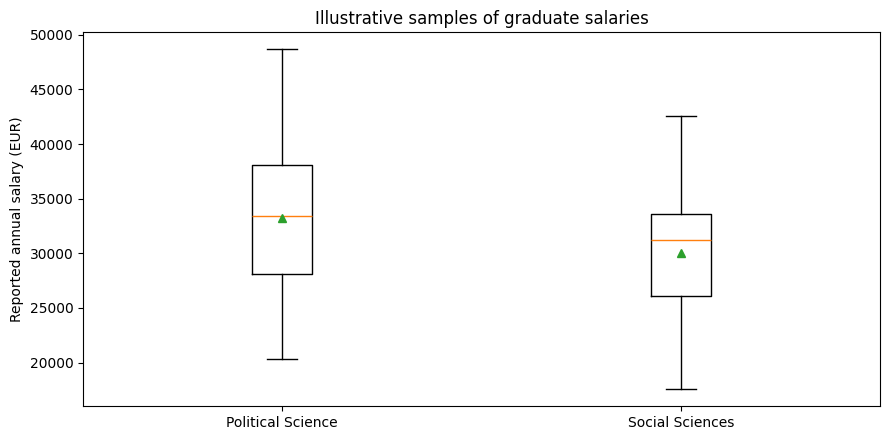

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

url = (
    "https://userpage.fu-berlin.de/"
    "soga/data/raw-data/students.csv"
)
students = pd.read_csv(url)

# Keep female graduates in the two specified subjects.
graduated = pd.to_numeric(students["graduated"], errors="coerce")
base = students.loc[
    (graduated == 1) & (students["gender"] == "Female")
].copy()
base["salary"] = pd.to_numeric(base["salary"], errors="coerce")

political = base.loc[
    base["major"] == "Political Science", "salary"
].dropna()
social = base.loc[
    base["major"] == "Social Sciences", "salary"
].dropna()

n = min(50, len(political), len(social))
if n < 2:
    raise ValueError("Not enough nonmissing salaries in both groups")

sample_p = political.sample(n=n, random_state=9).to_numpy()
sample_s = social.sample(n=n, random_state=9).to_numpy()

result = stats.ttest_ind(sample_p, sample_s, equal_var=False)

mean_difference = sample_p.mean() - sample_s.mean()
s1 = sample_p.std(ddof=1)
s2 = sample_s.std(ddof=1)
se = np.sqrt(s1**2 / n + s2**2 / n)

v1, v2 = s1**2 / n, s2**2 / n
df = (v1 + v2)**2 / (v1**2 / (n - 1) + v2**2 / (n - 1))
margin = stats.t.ppf(0.975, df) * se

print("Observations per group:", n)
print(f"Political Science mean: {sample_p.mean():.2f}")
print(f"Social Sciences mean: {sample_s.mean():.2f}")
print(f"Difference (Political - Social): {mean_difference:.2f}")
print(f"Welch t-statistic: {result.statistic:.4f}")
print(f"Welch p-value: {result.pvalue:.4f}")
print(f"Welch degrees of freedom: {df:.2f}")
print(
    f"95% CI for mean difference: "
    f"[{mean_difference-margin:.2f}, {mean_difference+margin:.2f}]"
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([sample_p, sample_s], showmeans=True)
ax.set_xticks([1, 2], ["Political Science", "Social Sciences"])
ax.set_ylabel("Reported annual salary (EUR)")
ax.set_title("Illustrative samples of graduate salaries")
fig.tight_layout()
fig.savefig(
    "../../images/welch_graduate_salary_comparison.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

# Experiment: change the random seed and sample size.
# Do the estimated mean difference and p-value change?